# Holdout evaluation

* 대상: 후보 선정·최종 학습 뒤 holdout 60,012명
* 확인: 저장된 Qini·상위 30% 구매율 차이·점수 10분위
* 실행 범위: 공개 집계값 검산; 행별 예측 파일이 필요한 Qini 곡선 재계산 제외

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
candidates = [p for base in (Path.cwd(), *Path.cwd().parents) for p in (base, base / "code")]
CODE = next(p for p in candidates if (p / "evidence").is_dir() and (p / "modeling").is_dir())
PROJECT = CODE.parent

result = json.loads((CODE / "evidence/final/holdout_eval/holdout_eval.json").read_text())
metrics = result["metrics"]
heterogeneity = json.loads((CODE / "evidence/post_heterogeneity/heterogeneity.json").read_text())
deciles = pd.read_csv(CODE / "evidence/post_heterogeneity/deciles.csv")
assert metrics["n"] == int(deciles["n"].sum()) == 60012
assert deciles["decile"].tolist() == list(range(1, 11))
overall = float(heterogeneity["overall_uplift_pp"])
top30 = float(metrics["uplift_at_30_pp"])
print(f"Holdout {metrics['n']:,}명 · 수신군 {metrics['n_treated']:,}명")
display(pd.DataFrame({"지표": ["Qini", "상위 30% 구매율 차이 (%p)", "전체 구매율 차이 (%p)", "두 차이의 비율"], "값": [f"{metrics['qini']:.4f}", f"{top30:+.2f}", f"{overall:+.2f}", f"{top30 / overall:.2f}배"]}))

Holdout 60,012명 · 수신군 29,995명


,지표,값
0,Qini,0.0160
1,상위 30% 구매율 차이 (%p),+7.37
2,전체 구매율 차이 (%p),+3.32
3,두 차이의 비율,2.22배


## 최종 학습·holdout 평가 실행 (선택)

* 순서: 선정 모델 재학습·봉인 → holdout 구매 결과 평가 → Qini 그림
* 입력: `models.ipynb`까지 완료한 비공개 작업 폴더
* 실행 조건: `X5_WORK_DIR` 지정 후 `X5_RUN_FULL=1`


In [ ]:
import os
import subprocess
import sys

if os.environ.get("X5_RUN_FULL") == "1":
    assert os.environ.get("X5_WORK_DIR")
    work = Path(os.environ["X5_WORK_DIR"]).resolve()
    assert (work / "results/selection/selection_result.json").is_file()
    commands = [
        ["final.py", "--selection-dir", "results/selection", "--out-dir", "results/final"],
        ["holdout_eval.py", "--final-dir", "results/final"],
    ]
    for command in commands:
        log = work / "logs" / f"{Path(command[0]).stem}.log"
        log.parent.mkdir(parents=True, exist_ok=True)
        with log.open("w") as output:
            subprocess.run([sys.executable, str(work / "modeling" / command[0]), *command[1:]],
                           cwd=work, stdout=output, stderr=subprocess.STDOUT, check=True)
        print(command[0], "완료 ·", log)
    local = json.loads((work / "results/final/holdout_eval/holdout_eval.json").read_text())
    assert abs(local["metrics"]["qini"] - metrics["qini"]) < 1e-12
    print("holdout Qini 검산:", round(local["metrics"]["qini"], 6))
else:
    print("최종 학습·평가 실행: 생략 · 저장된 holdout 결과 확인")


## Qini 곡선

* 왼쪽: train 후보 비교
* 오른쪽: 선정 모델의 holdout 순위 평가
* 그림 입력: 공개 폴더에 없는 행별 예측 파일; 저장된 그림 표시

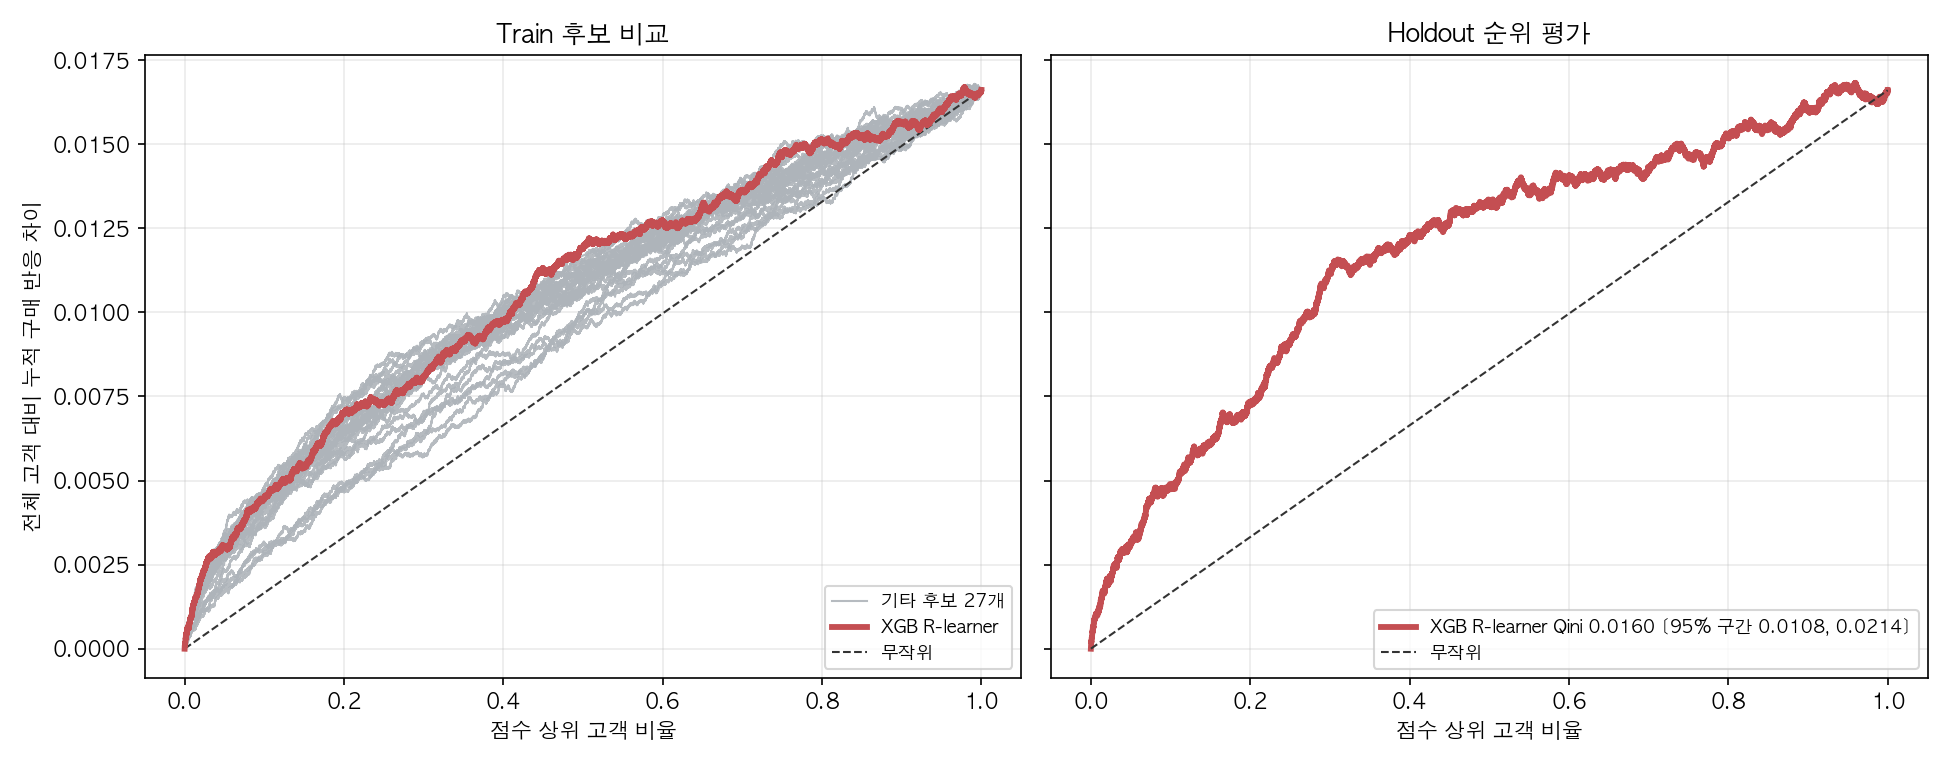

In [2]:
display(Image(filename=str(PROJECT / "figs/qini_train_holdout.png")))

In [ ]:
# 원본 예측 파일이 있을 때 Qini 곡선 재생성
if os.environ.get("X5_RUN_FULL") == "1":
    import matplotlib.pyplot as plt
    sys.path.insert(0, str(work / "modeling"))
    from qini import qini_curve_coords, qini_from_coords

    split = pd.read_parquet(work / "data/splits/split.parquet", columns=["client_id", "split"])
    train_ids = split.loc[split.split == "train", "client_id"]
    labels = pd.read_csv(work / "data/og/retailhero-uplift/data/uplift_train.csv",
                         usecols=["client_id", "treatment_flg", "target"], dtype={"client_id": str})
    train = labels.loc[labels.client_id.isin(train_ids)].set_index("client_id")
    assert len(train) == 140027 and train.index.is_unique

    ranking_local = pd.read_csv(work / "results/selection/qini_table.csv").set_index("candidate")
    selected = json.loads((work / "results/selection/selection_result.json").read_text())["selected"]
    assert len(ranking_local) == 28 and selected in ranking_local.index
    plt.rcParams["font.family"] = ["AppleGothic", "DejaVu Sans"]
    plt.rcParams["axes.unicode_minus"] = False
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.1), sharey=True)
    studies = work / "results/nested/studies"
    for candidate in ranking_local.index:
        parts = [pd.read_parquet(studies / f"{candidate}__outer{k}.outer_pred.parquet") for k in range(5)]
        pred = pd.concat(parts, ignore_index=True)
        assert len(pred) == len(train) and pred.client_id.is_unique
        truth = train.loc[pred.client_id]
        curve = qini_curve_coords(truth.target, pred.uplift, truth.treatment_flg)
        if candidate == selected:
            axes[0].plot(curve["x"], curve["y"], color="#C44E52", lw=2.8,
                         label="XGB R-learner", zorder=3)
        else:
            axes[0].plot(curve["x"], curve["y"], color="#AEB4BA", lw=1.0, alpha=0.9,
                         label="기타 후보 27개" if candidate == ranking_local.index[0] else None)
    axes[0].plot(curve["x_random"], curve["y_random"], "--", color="#333333", lw=1.0, label="무작위")

    pred = pd.read_parquet(work / "results/final/holdout_eval/holdout_predictions.parquet")
    curve = qini_curve_coords(pred.target, pred.uplift, pred.treatment_flg)
    assert abs(qini_from_coords(curve) - local["metrics"]["qini"]) < 1e-12
    lo, hi = local["metrics"]["qini_ci95"]
    axes[1].plot(curve["x"], curve["y"], color="#C44E52", lw=2.8,
                 label=f"XGB R-learner Qini {local['metrics']['qini']:.4f} [95% 구간 {lo:.4f}, {hi:.4f}]")
    axes[1].plot(curve["x_random"], curve["y_random"], "--", color="#333333", lw=1.0, label="무작위")
    for ax, title in zip(axes, ("Train 후보 비교", "Holdout 순위 평가")):
        ax.set_title(title)
        ax.set_xlabel("점수 상위 고객 비율")
        ax.grid(alpha=0.25)
        ax.legend(loc="lower right", fontsize=8.5)
    axes[0].set_ylabel("전체 고객 대비 누적 구매 반응 차이")
    fig.tight_layout()
    figure = work / "figs/qini_train_holdout.png"
    figure.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure, dpi=150)
    plt.show()
    print("Qini 그림:", figure)


## 점수 10분위

* 상위 30% `+7.37%p`: 수신군·미수신군을 각각 점수로 자른 결과
* 1~3분위 합산: 전체 고객을 분위로 나눈 결과; 상위 30%와 집계 방식 다름

,분위,고객 수,수신군,rate_treated,rate_control,구매율 차이 (%p),ci_lo_pp,ci_hi_pp
0,1,6002,3004,0.556258,0.460974,9.528434,7.063442,12.048291
1,2,6001,3040,0.555592,0.506248,4.934422,2.444013,7.393529
2,3,6001,2996,0.592790,0.514143,7.864729,5.415013,10.378257
3,4,6001,2990,0.590635,0.568250,2.238570,-0.148783,4.670146
4,5,6001,2999,0.629877,0.610593,1.928369,-0.523609,4.336162
5,6,6002,2999,0.651884,0.634699,1.718533,-0.599782,4.210553
6,7,6001,2973,0.673058,0.667107,0.595052,-1.714634,2.783332
7,8,6001,3015,0.731343,0.712659,1.868421,-0.332799,4.066655
8,9,6001,2966,0.741403,0.722241,1.916204,-0.237955,4.206770
9,10,6001,3013,0.644208,0.633534,1.067429,-1.257643,3.462574


1~3분위 합산 구매율 차이: +7.44%p


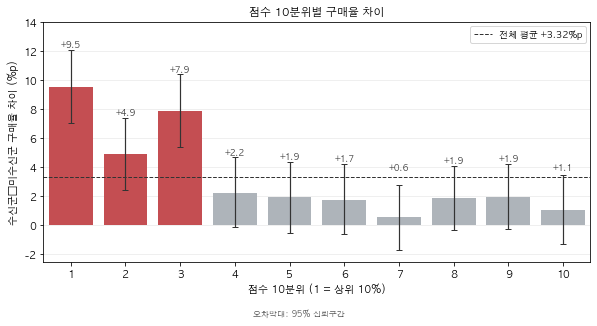

In [3]:
import matplotlib.pyplot as plt
import numpy as np

display(deciles[["decile", "n", "n_treated", "rate_treated", "rate_control", "uplift_pp", "ci_lo_pp", "ci_hi_pp"]]
        .rename(columns={"decile": "분위", "n": "고객 수", "n_treated": "수신군", "uplift_pp": "구매율 차이 (%p)"}))
top = deciles.head(3)
treated_rate = (top.n_treated * top.rate_treated).sum() / top.n_treated.sum()
control_n = top.n - top.n_treated
control_rate = (control_n * top.rate_control).sum() / control_n.sum()
print(f"1~3분위 합산 구매율 차이: {100 * (treated_rate - control_rate):+.2f}%p")

plt.rcParams["font.family"] = ["AppleGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
fig, ax = plt.subplots(figsize=(8.4, 4.5))
vals = deciles.uplift_pp.to_numpy()
ax.bar(deciles.decile, vals, color=["#C44E52" if i <= 3 else "#AEB4BA" for i in deciles.decile])
ax.errorbar(deciles.decile, vals,
            yerr=[vals - deciles.ci_lo_pp.to_numpy(), deciles.ci_hi_pp.to_numpy() - vals],
            fmt="none", ecolor="#333333", capsize=3, lw=1.2)
for x, value, hi in zip(deciles.decile, vals, deciles.ci_hi_pp):
    ax.text(x, max(hi + 0.15, overall + 0.45), f"{value:+.1f}",
            ha="center", fontsize=8.5, color="#333333")
ax.axhline(overall, color="#333333", ls="--", lw=1.0, label=f"전체 평균 {overall:+.2f}%p")
ax.set_xticks(np.arange(1, 11))
ax.set_xlim(0.5, 10.5)
ax.set_ylim(-2.5, 14)
ax.set_xlabel("점수 10분위 (1 = 상위 10%)")
ax.set_ylabel("수신군−미수신군 구매율 차이 (%p)")
ax.set_title("점수 10분위별 구매율 차이", fontsize=11)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(loc="upper right", fontsize=9)
fig.text(0.5, 0.01, "오차막대: 95% 신뢰구간", ha="center", fontsize=8, color="#555555")
fig.tight_layout(rect=(0, 0.045, 1, 1))
plt.show()

* 해석 범위: holdout에서 관측한 두 구매율 차이의 비율
* 제외: 실제 캠페인 적용 성과·매출 증가율